# 02 · Exploración y análisis preliminar (Programación, Unidad 1)

| ID del enunciado | Qué cubre | Sección |
|---|---|---|
| **P1.1** / **P1.E1** | Configurar el entorno (Jupyter / Google Colab) | 1 |
| **P1.2** / **P1.E1** | Importar Pandas, NumPy, Matplotlib y Seaborn | 2 |
| **P1.3** / **P1.E2** | Cargar y explorar el conjunto de datos financieros | 3 |
| **P1.4** / **P1.E3** | Operaciones básicas: selección, filtrado, ordenamiento y agregaciones | 4 |
| **P1.5** / **P1.E4** | Primeras visualizaciones: histogramas, dispersión, boxplots y barras | 5 |
| **E3** | Uso de datos realistas del sector financiero | 3 |

Los nulos y duplicados **solo se reportan** aquí; se tratan en el notebook 03.

## 1. P1.1 · Entorno

**Jupyter local:** desde la carpeta `Back/` ejecutar `pip install -r requirements.txt` y luego `jupyter lab`; abrir `notebooks/02_exploracion_preliminar.ipynb` y usar *Restart & Run All*.

**Google Colab:**
1. Subir el notebook a Colab (`Archivo > Subir notebook`).
2. Opción A, subir el CSV: `from google.colab import files; files.upload()` y seleccionar `credit_risk.csv`.
   Opción B, montar Drive: `from google.colab import drive; drive.mount('/content/drive')` y apuntar `RAW_DATA_PATH` a la ruta del CSV en Drive.
3. Las librerías usadas (pandas, numpy, matplotlib, seaborn, scikit-learn) ya vienen instaladas en Colab.

In [1]:
import sys, platform
import numpy as np, pandas as pd, matplotlib, seaborn as sns, sklearn
print("Python      :", sys.version.split()[0], "|", platform.system(), platform.release())
for nombre, mod in {"numpy": np, "pandas": pd, "matplotlib": matplotlib, "seaborn": sns, "scikit-learn": sklearn}.items():
    print(f"{nombre:<12}: {mod.__version__}")
try:
    import google.colab  # noqa: F401
    print("Entorno: Google Colab")
except ImportError:
    print("Entorno: Jupyter local")

Python      : 3.10.7 | Windows 10
numpy       : 1.26.4
pandas      : 2.3.3
matplotlib  : 3.10.8
seaborn     : 0.13.2
scikit-learn: 1.4.2
Entorno: Jupyter local


## 2. P1.2 · Librerías y configuración
Se importan las cuatro librerías del enunciado (`pandas as pd`, `numpy as np`, `matplotlib.pyplot as plt`, `seaborn as sns`) y se configura el estilo de los gráficos y la visualización de tablas. Las rutas son **relativas**: se busca la carpeta `db/` subiendo desde el directorio del notebook.

In [2]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def buscar_raiz(inicio: Path = Path.cwd()) -> Path:
    """Sube por los directorios hasta encontrar db/credit_risk.csv (rutas relativas, sin rutas absolutas)."""
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv; ejecute el notebook desde Back/notebooks/")

PROJECT_ROOT = buscar_raiz()
RAW_DATA_PATH = PROJECT_ROOT / "db" / "credit_risk.csv"      # equivalente a config.DATA_PATH
PROCESSED_DIR = PROJECT_ROOT / "db" / "processed"
TARGET, ID_COL, TEXT_COL = "default", "id_cliente", "texto_solicitud"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.options.display.max_columns = 50
pd.options.display.width = 160
pd.options.display.float_format = "{:,.3f}".format
print("Raíz del proyecto (relativa al notebook):", Path("..", "..").as_posix())

Raíz del proyecto (relativa al notebook): ../..


## 3. P1.3 · Carga e inspección del dataset

In [3]:
df = pd.read_csv(RAW_DATA_PATH)
print("Dimensiones (filas, columnas):", df.shape)
df.head()

Dimensiones (filas, columnas): (12144, 21)


,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
0,CLI_006413,23,M,Union_libre,Tecnico,Pensionado,5.000,4,Arriendo,"1,840,000.000","10,634,000.000",12,34.100,Consolidacion_deuda,0,1,0.564,805.000,0.282,Quisiera acceder a financiacion para reorganiz...,0
1,CLI_008728,79,F,Casado,Secundaria,Empleado,56.800,3,Propia,"3,954,000.000","14,842,000.000",24,13.800,Libre_inversion,4,0,0.470,738.000,0.555,Necesito el prestamo para una inversion person...,0
2,CLI_002268,63,F,Union_libre,Primaria,Independiente,7.000,3,Propia,"1,187,000.000","3,943,000.000",6,14.200,Libre_inversion,2,0,0.519,779.000,0.750,Requiero el prestamo para cubrir gastos person...,0
3,CLI_008456,29,F,Soltero,Secundaria,Empleado,0.200,0,Arriendo,"1,181,000.000","7,418,000.000",48,41.200,Negocio,1,2,0.466,639.000,0.547,Pido este credito con el fin de capital de tra...,1
4,CLI_010961,65,M,Soltero,Secundaria,Empleado,NaN,1,Arriendo,"2,303,000.000","9,208,000.000",24,15.300,Libre_inversion,2,0,0.273,752.000,0.317,Solicito este credito para un proyecto persona...,0


In [4]:
df.tail()

,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
12139,CLI_011965,33,F,Casado,Universitario,Empleado,5.400,0,NaN,"3,048,000.000","78,878,000.000",36,25.400,Vivienda,2,0,1.500,703.000,0.229,Solicito este credito para hacer mejoras en mi...,0
12140,CLI_005192,75,F,Soltero,Tecnico,Empleado,NaN,2,Arriendo,"3,393,000.000","6,904,000.000",36,33.000,Libre_inversion,1,0,0.061,766.000,0.064,Solicito este credito para gastos varios del h...,0
12141,CLI_005391,29,F,Casado,Secundaria,Empleado,7.300,3,Propia,"4,159,000.000","23,374,000.000",24,34.500,Consolidacion_deuda,0,0,0.405,836.000,0.000,Requiero el prestamo para reorganizar mis obli...,0
12142,CLI_000861,78,F,Casado,Primaria,Empleado,40.300,0,Arriendo,"1,534,000.000","9,563,000.000",60,11.500,Vehiculo,0,0,0.476,710.000,0.365,Necesito el prestamo para adquirir un vehiculo...,0
12143,CLI_007271,37,F,Viudo,Secundaria,Empleado,8.900,4,Propia,"2,899,000.000","5,234,000.000",36,41.400,Libre_inversion,1,0,0.372,690.000,0.447,Pido este credito con el fin de gastos varios ...,1


In [5]:
df.sample(5, random_state=RANDOM_STATE)

,id_cliente,edad,sexo,estado_civil,nivel_educativo,situacion_laboral,antiguedad_laboral_anios,personas_a_cargo,tipo_vivienda,ingreso_mensual,monto_credito,plazo_meses,tasa_interes_anual,proposito,num_creditos_activos,moras_ultimos_12m,relacion_deuda_ingreso,puntaje_buro,uso_cupo_tarjetas,texto_solicitud,default
6412,CLI_001244,48,M,Union_libre,Secundaria,Empleado,3.400,3,Propia,"2,144,000.000","13,232,000.000",12,15.200,Vehiculo,2,0,0.243,835.000,0.302,Pido este credito con el fin de adquirir un ve...,0
8727,CLI_001402,33,F,Divorciado,Primaria,Independiente,8.000,0,Arriendo,"2,001,000.000","64,039,000.000",24,12.400,Vivienda,3,1,1.500,685.000,0.572,Pido este credito con el fin de remodelar mi c...,0
2267,CLI_004194,20,F,Soltero,Universitario,Independiente,1.800,1,Arriendo,"2,906,000.000","27,756,000.000",48,34.900,Negocio,2,0,0.870,799.000,0.604,Necesito el prestamo para capital de trabajo p...,1
8455,CLI_003172,77,M,Union_libre,Primaria,Empleado,16.900,1,Arriendo,"1,490,000.000","6,689,000.000",36,12.000,Libre_inversion,0,0,0.242,950.000,0.137,Requiero el prestamo para gastos varios del ho...,0
10960,CLI_005960,73,F,Soltero,Universitario,Empleado,17.700,0,Propia,"3,376,000.000","13,844,000.000",48,32.800,Consolidacion_deuda,1,0,0.518,849.000,0.106,Pido este credito con el fin de unificar mis d...,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12144 entries, 0 to 12143
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_cliente                12144 non-null  object 
 1   edad                      12144 non-null  int64  
 2   sexo                      12144 non-null  object 
 3   estado_civil              12144 non-null  object 
 4   nivel_educativo           12144 non-null  object 
 5   situacion_laboral         11650 non-null  object 
 6   antiguedad_laboral_anios  11026 non-null  float64
 7   personas_a_cargo          12144 non-null  int64  
 8   tipo_vivienda             11757 non-null  object 
 9   ingreso_mensual           11395 non-null  float64
 10  monto_credito             12144 non-null  float64
 11  plazo_meses               12144 non-null  int64  
 12  tasa_interes_anual        12144 non-null  float64
 13  proposito                 12144 non-null  object 
 14  num_cr

In [7]:
# Tipos de dato agrupados
df.dtypes.astype(str).value_counts().rename("n_columnas").to_frame()

,n_columnas
object,8
float64,7
int64,6


In [8]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
edad,"12,144.000",49.131,23.646,1.000,33.000,49.000,65.000,999.000
antiguedad_laboral_anios,"11,026.000",13.163,13.199,0.000,2.500,8.900,20.000,62.000
personas_a_cargo,"12,144.000",1.610,1.547,0.000,0.000,1.000,2.000,6.000
ingreso_mensual,"11,395.000","2,624,177.095","2,035,883.682","312,000.000","1,529,500.000","2,237,000.000","3,203,000.000","64,540,000.000"
monto_credito,"12,144.000","21,541,744.236","31,447,367.714","1,000,000.000","6,986,000.000","12,281,000.000","23,411,000.000","1,033,300,000.000"
plazo_meses,"12,144.000",32.572,19.549,6.000,18.000,24.000,48.000,84.000
tasa_interes_anual,"12,144.000",26.120,9.236,10.000,18.100,26.200,34.100,42.000
num_creditos_activos,"12,144.000",1.577,1.258,0.000,1.000,1.000,2.000,8.000
moras_ultimos_12m,"12,144.000",0.509,0.911,0.000,0.000,0.000,1.000,10.000
relacion_deuda_ingreso,"11,532.000",0.622,0.375,0.000,0.360,0.553,0.792,1.500


In [9]:
# Estadísticas descriptivas de las variables categóricas
df.describe(include="object").T

,count,unique,top,freq
id_cliente,12144,12000,CLI_004706,2
sexo,12144,2,M,6273
estado_civil,12144,5,Soltero,4569
nivel_educativo,12144,5,Secundaria,3551
situacion_laboral,11650,4,Empleado,6427
tipo_vivienda,11757,3,Arriendo,4969
proposito,12144,6,Libre_inversion,3430
texto_solicitud,11904,4453,Necesito el prestamo para un proyecto personal...,20


In [10]:
# Valores únicos por columna
df.nunique().sort_values().rename("valores_unicos").to_frame().T

,default,sexo,tipo_vivienda,situacion_laboral,estado_civil,nivel_educativo,proposito,personas_a_cargo,plazo_meses,num_creditos_activos,moras_ultimos_12m,edad,tasa_interes_anual,antiguedad_laboral_anios,puntaje_buro,uso_cupo_tarjetas,relacion_deuda_ingreso,ingreso_mensual,texto_solicitud,monto_credito,id_cliente
valores_unicos,2,2,3,4,5,5,6,7,9,9,11,68,321,580,616,992,1394,4277,4453,10082,12000


In [11]:
# Valores nulos (solo se reportan; se tratan en el notebook 03)
nulos = pd.DataFrame({"nulos": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)
print(f"Columnas con nulos: {len(nulos)} | Total de celdas nulas: {df.isna().sum().sum():,}")
nulos

Columnas con nulos: 7 | Total de celdas nulas: 4,088


,nulos,pct
antiguedad_laboral_anios,1118,9.210
ingreso_mensual,749,6.170
relacion_deuda_ingreso,612,5.040
situacion_laboral,494,4.070
puntaje_buro,488,4.020
tipo_vivienda,387,3.190
texto_solicitud,240,1.980


In [12]:
# Duplicados (solo se reportan)
dup_exactos = df.duplicated().sum()
dup_id = df[ID_COL].duplicated().sum()
print(f"Filas duplicadas exactas: {dup_exactos} ({dup_exactos/len(df):.2%})")
print(f"IDs repetidos           : {dup_id}")
# Valores fuera de rango (se corrigen en el notebook 03)
print("Edades fuera de 18-100  :", (~df["edad"].between(18, 100)).sum(), "->", sorted(df.loc[~df["edad"].between(18, 100), "edad"].unique()))

Filas duplicadas exactas: 144 (1.19%)
IDs repetidos           : 144
Edades fuera de 18-100  : 25 -> [1, 2, 120, 150, 999]


In [13]:
# Distribución de la variable objetivo
dist = pd.DataFrame({"clientes": df[TARGET].value_counts(), "proporcion": df[TARGET].value_counts(normalize=True).round(4)})
dist.index = dist.index.map({0: "0 = Pagó", 1: "1 = Impago"})
print(f"Tasa de default: {df[TARGET].mean():.2%}")
dist

Tasa de default: 35.63%


,clientes,proporcion
default,,
0 = Pagó,7817,0.644
1 = Impago,4327,0.356


**Lectura:** el dataset tiene ~12.1 mil filas y 21 columnas (12 numéricas, 7 categóricas, 1 texto, 1 objetivo). Hay **7 columnas con nulos** (entre ~2 % y ~9 %), **144 filas duplicadas** y **25 edades imposibles** (1, 2, 120, 150, 999). La clase impago representa **≈ 35.6 %**, un desbalance moderado que justifica la estratificación en la división train/test. Los máximos de `ingreso_mensual` y `monto_credito` son muy superiores al percentil 99 (errores de digitación con un cero de más), lo que anticipa atípicos.

## 4. P1.4 · Operaciones básicas
### 4.1 Selección

In [14]:
# Por nombre
df[["id_cliente", "edad", "ingreso_mensual", "monto_credito", "default"]].head(3)

,id_cliente,edad,ingreso_mensual,monto_credito,default
0,CLI_006413,23,"1,840,000.000","10,634,000.000",0
1,CLI_008728,79,"3,954,000.000","14,842,000.000",0
2,CLI_002268,63,"1,187,000.000","3,943,000.000",0


In [15]:
# Por tipo de dato
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(include="object").columns.drop([ID_COL, TEXT_COL]).tolist()
print("Numéricas  :", numericas)
print("Categóricas:", categoricas)

Numéricas  : ['edad', 'antiguedad_laboral_anios', 'personas_a_cargo', 'ingreso_mensual', 'monto_credito', 'plazo_meses', 'tasa_interes_anual', 'num_creditos_activos', 'moras_ultimos_12m', 'relacion_deuda_ingreso', 'puntaje_buro', 'uso_cupo_tarjetas', 'default']
Categóricas: ['sexo', 'estado_civil', 'nivel_educativo', 'situacion_laboral', 'tipo_vivienda', 'proposito']


In [16]:
# loc (etiquetas) e iloc (posiciones)
display(df.loc[df.index[:3], ["edad", "proposito", "default"]])
display(df.iloc[:3, [1, 9, 10, -1]])

,edad,proposito,default
0,23,Consolidacion_deuda,0
1,79,Libre_inversion,0
2,63,Libre_inversion,0


,edad,ingreso_mensual,monto_credito,default
0,23,"1,840,000.000","10,634,000.000",0
1,79,"3,954,000.000","14,842,000.000",0
2,63,"1,187,000.000","3,943,000.000",0


### 4.2 Filtrado

In [17]:
# Condición simple: clientes con moras en los últimos 12 meses
con_moras = df[df["moras_ultimos_12m"] > 0]
print(f"Con moras: {len(con_moras):,} clientes | tasa de default {con_moras[TARGET].mean():.2%} vs {df[TARGET].mean():.2%} global")

# Condición compuesta: ingreso bajo (< p25) y monto alto (> p75)
p25_ing, p75_monto = df["ingreso_mensual"].quantile(0.25), df["monto_credito"].quantile(0.75)
riesgosos = df[(df["ingreso_mensual"] < p25_ing) & (df["monto_credito"] > p75_monto)]
print(f"Ingreso < {p25_ing:,.0f} y monto > {p75_monto:,.0f}: {len(riesgosos):,} clientes | default {riesgosos[TARGET].mean():.2%}")

Con moras: 4,074 clientes | tasa de default 59.67% vs 35.63% global
Ingreso < 1,529,500 y monto > 23,411,000: 263 clientes | default 42.97%


In [18]:
# query(): puntaje de buró bajo y alto uso del cupo de tarjetas
q = df.query("puntaje_buro < 600 and uso_cupo_tarjetas > 0.7")
print(f"query -> {len(q):,} clientes | tasa de default {q[TARGET].mean():.2%}")
q[["edad", "puntaje_buro", "uso_cupo_tarjetas", "default"]].head()

query -> 1,177 clientes | tasa de default 87.68%


,edad,puntaje_buro,uso_cupo_tarjetas,default
16,49,545.000,0.717,1
22,48,471.000,1.000,1
27,22,598.000,0.701,1
28,38,564.000,0.718,1
62,39,548.000,0.745,1


### 4.3 Ordenamiento

In [19]:
# Por una columna: los 5 créditos de mayor monto (posibles errores de digitación)
df.sort_values("monto_credito", ascending=False)[["id_cliente", "ingreso_mensual", "monto_credito", "default"]].head()

,id_cliente,ingreso_mensual,monto_credito,default
8775,CLI_008419,"5,925,000.000","1,033,300,000.000",0
9039,CLI_011363,"4,709,000.000","914,640,000.000",1
4701,CLI_009476,"3,847,000.000","717,650,000.000",0
4542,CLI_003849,"2,527,000.000","563,340,000.000",1
11683,CLI_007988,"4,031,000.000","524,450,000.000",1


In [20]:
# Por varias columnas: más moras primero y, a igualdad, menor puntaje de buró
df.sort_values(["moras_ultimos_12m", "puntaje_buro"], ascending=[False, True])[
    ["id_cliente", "moras_ultimos_12m", "puntaje_buro", "default"]].head()

,id_cliente,moras_ultimos_12m,puntaje_buro,default
9417,CLI_011326,10,150.000,1
11979,CLI_004637,9,237.000,1
7970,CLI_002775,9,276.000,1
7815,CLI_006742,9,278.000,1
4715,CLI_009220,9,286.000,1


### 4.4 Agregaciones

In [21]:
# groupby + agg: tasa de impago por situación laboral
(df.groupby("situacion_laboral")
   .agg(clientes=("default", "size"), tasa_default=("default", "mean"),
        ingreso_mediano=("ingreso_mensual", "median"), puntaje_medio=("puntaje_buro", "mean"))
   .sort_values("tasa_default", ascending=False))

,clientes,tasa_default,ingreso_mediano,puntaje_medio
situacion_laboral,,,,
Desempleado,813,0.620,"1,005,000.000",605.341
Independiente,3295,0.391,"2,326,000.000",693.701
Empleado,6427,0.328,"2,347,000.000",721.157
Pensionado,1115,0.240,"2,300,000.000",755.146


In [22]:
# pivot_table: tasa de impago por nivel educativo y tipo de vivienda
orden_edu = ["Primaria", "Secundaria", "Tecnico", "Universitario", "Posgrado"]
pd.pivot_table(df, values="default", index="nivel_educativo", columns="tipo_vivienda",
               aggfunc="mean").reindex(orden_edu).round(3)

tipo_vivienda,Arriendo,Familiar,Propia
nivel_educativo,,,
Primaria,0.508,0.457,0.371
Secundaria,0.444,0.429,0.329
Tecnico,0.401,0.370,0.305
Universitario,0.349,0.325,0.260
Posgrado,0.282,0.242,0.256


In [23]:
# value_counts(normalize=True): composición por propósito del crédito
df["proposito"].value_counts(normalize=True).round(3).rename("proporcion").to_frame()

,proporcion
proposito,
Libre_inversion,0.282
Vehiculo,0.174
Consolidacion_deuda,0.163
Vivienda,0.142
Negocio,0.140
Educacion,0.100


**Lectura:** el filtrado ya muestra señales fuertes: los clientes **con moras** y los que combinan **buró bajo y alto uso del cupo** tienen tasas de impago muy por encima del promedio. Por situación laboral, los **desempleados** (~62 %) e **independientes** (~39 %) superan a empleados (~33 %) y pensionados (~24 %). La tasa de impago **baja con el nivel educativo** y es menor en vivienda **propia**.

## 5. P1.5 · Visualizaciones exploratorias
Para que los errores de digitación no aplasten los gráficos, en ingreso y monto se muestran los valores hasta el **percentil 99** (los atípicos se tratan en los notebooks 03 y 04).

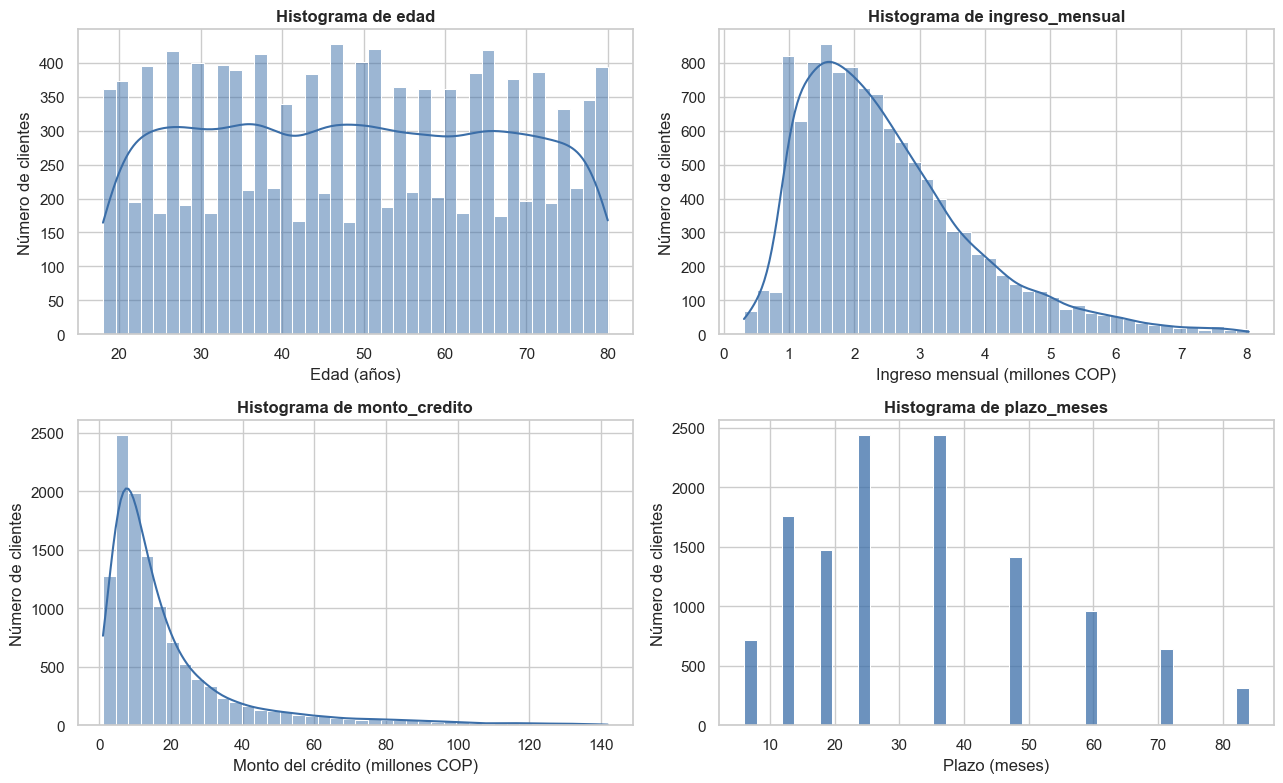

In [24]:
def hasta_p99(s):
    return s[s <= s.quantile(0.99)]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
specs = [("edad", df["edad"][df["edad"].between(18, 100)], "Edad (años)"),
         ("ingreso_mensual", hasta_p99(df["ingreso_mensual"].dropna()) / 1e6, "Ingreso mensual (millones COP)"),
         ("monto_credito", hasta_p99(df["monto_credito"]) / 1e6, "Monto del crédito (millones COP)"),
         ("plazo_meses", df["plazo_meses"], "Plazo (meses)")]
for ax, (col, serie, xlabel) in zip(axes.ravel(), specs):
    sns.histplot(serie, bins=40, kde=col != "plazo_meses", ax=ax, color="#3b6ea8")
    ax.set_title(f"Histograma de {col}")
    ax.set_xlabel(xlabel); ax.set_ylabel("Número de clientes")
plt.tight_layout(); plt.show()

**Interpretación:** la **edad** se reparte entre 18 y 80 años de forma bastante uniforme con más peso en adultos mayores; **ingreso** y **monto** tienen **asimetría positiva** (cola larga a la derecha), típica de variables monetarias, lo que sugiere transformación logarítmica o *capping*; el **plazo** es discreto (6, 12, 24, 36, 48, 60, 72, 84 meses) con predominio de plazos cortos y medios.

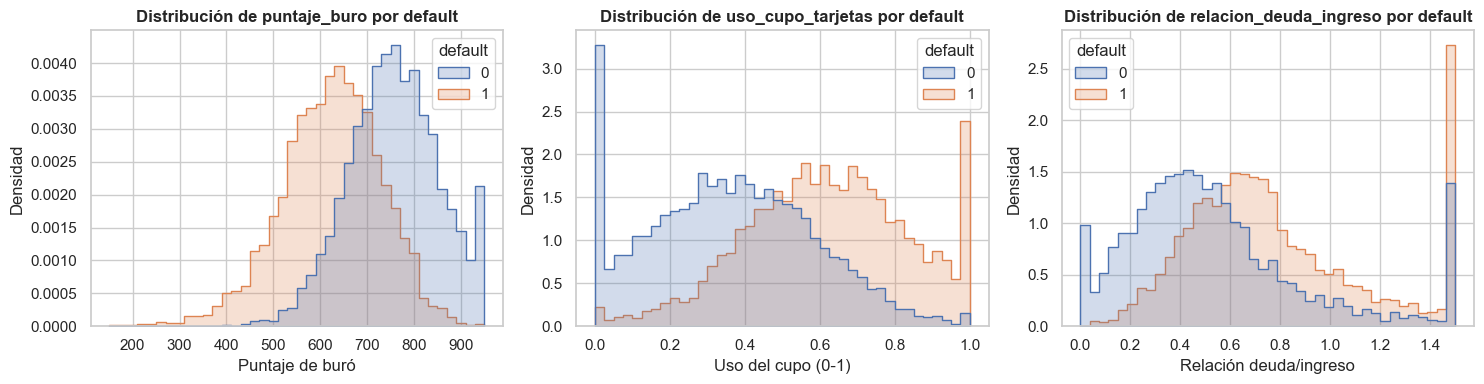

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, xl in zip(axes, ["puntaje_buro", "uso_cupo_tarjetas", "relacion_deuda_ingreso"],
                       ["Puntaje de buró", "Uso del cupo (0-1)", "Relación deuda/ingreso"]):
    sns.histplot(data=df, x=col, hue=TARGET, bins=40, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"Distribución de {col} por default"); ax.set_xlabel(xl); ax.set_ylabel("Densidad")
plt.tight_layout(); plt.show()

**Interpretación:** las tres variables separan bien las clases: los impagos se concentran en **puntajes de buró bajos**, **uso del cupo alto** y **relación deuda/ingreso alta**. Son candidatas fuertes a predictores.

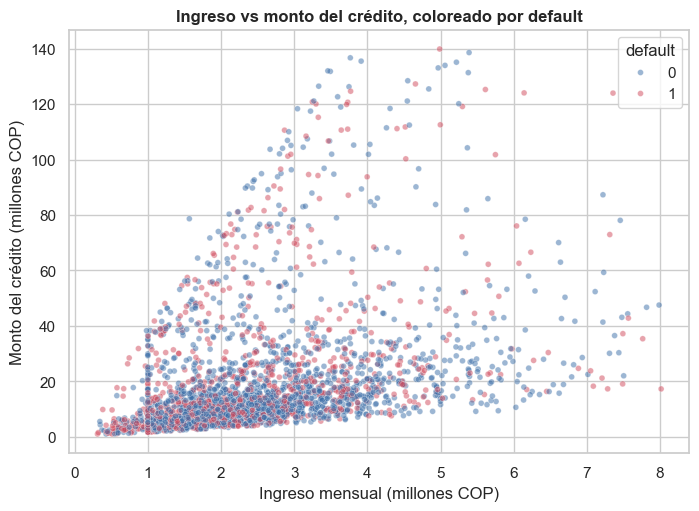

In [26]:
d = df[(df["ingreso_mensual"] <= df["ingreso_mensual"].quantile(0.99)) &
       (df["monto_credito"] <= df["monto_credito"].quantile(0.99))].sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=d, x=d["ingreso_mensual"] / 1e6, y=d["monto_credito"] / 1e6, hue=TARGET,
                alpha=0.5, s=18, palette={0: "#3b6ea8", 1: "#d1495b"}, ax=ax)
ax.set_title("Ingreso vs monto del crédito, coloreado por default")
ax.set_xlabel("Ingreso mensual (millones COP)"); ax.set_ylabel("Monto del crédito (millones COP)")
ax.legend(title="default"); plt.show()

**Interpretación:** el monto crece con el ingreso (relación positiva con mucha dispersión), pero los impagos (rojo) **no forman una región separada** en este plano: ingreso y monto por sí solos discriminan poco; lo que importa es la **relación entre ambos** (ratios cuota/ingreso y monto/ingreso, que se crean en el notebook 03).

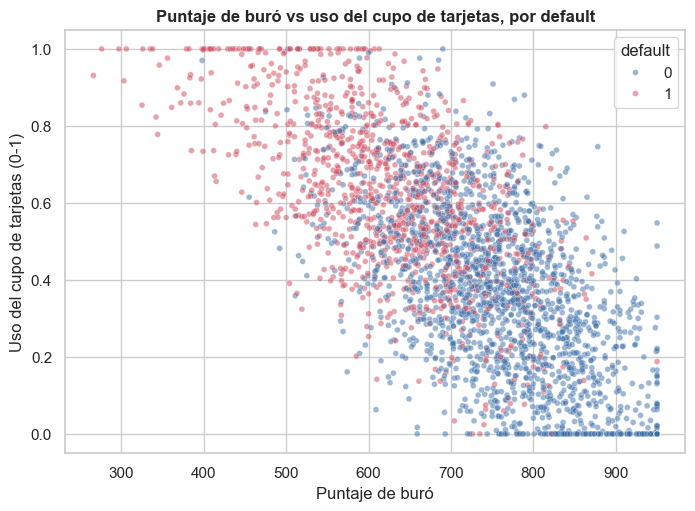

In [27]:
d2 = df.dropna(subset=["puntaje_buro"]).sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=d2, x="puntaje_buro", y="uso_cupo_tarjetas", hue=TARGET, alpha=0.5, s=18,
                palette={0: "#3b6ea8", 1: "#d1495b"}, ax=ax)
ax.set_title("Puntaje de buró vs uso del cupo de tarjetas, por default")
ax.set_xlabel("Puntaje de buró"); ax.set_ylabel("Uso del cupo de tarjetas (0-1)")
ax.legend(title="default"); plt.show()

**Interpretación:** aquí sí hay separación visible: los impagos se acumulan en la esquina de **buró bajo y uso del cupo alto**, mientras que los buenos pagadores dominan la zona de buró alto y uso bajo. Las dos variables se complementan.

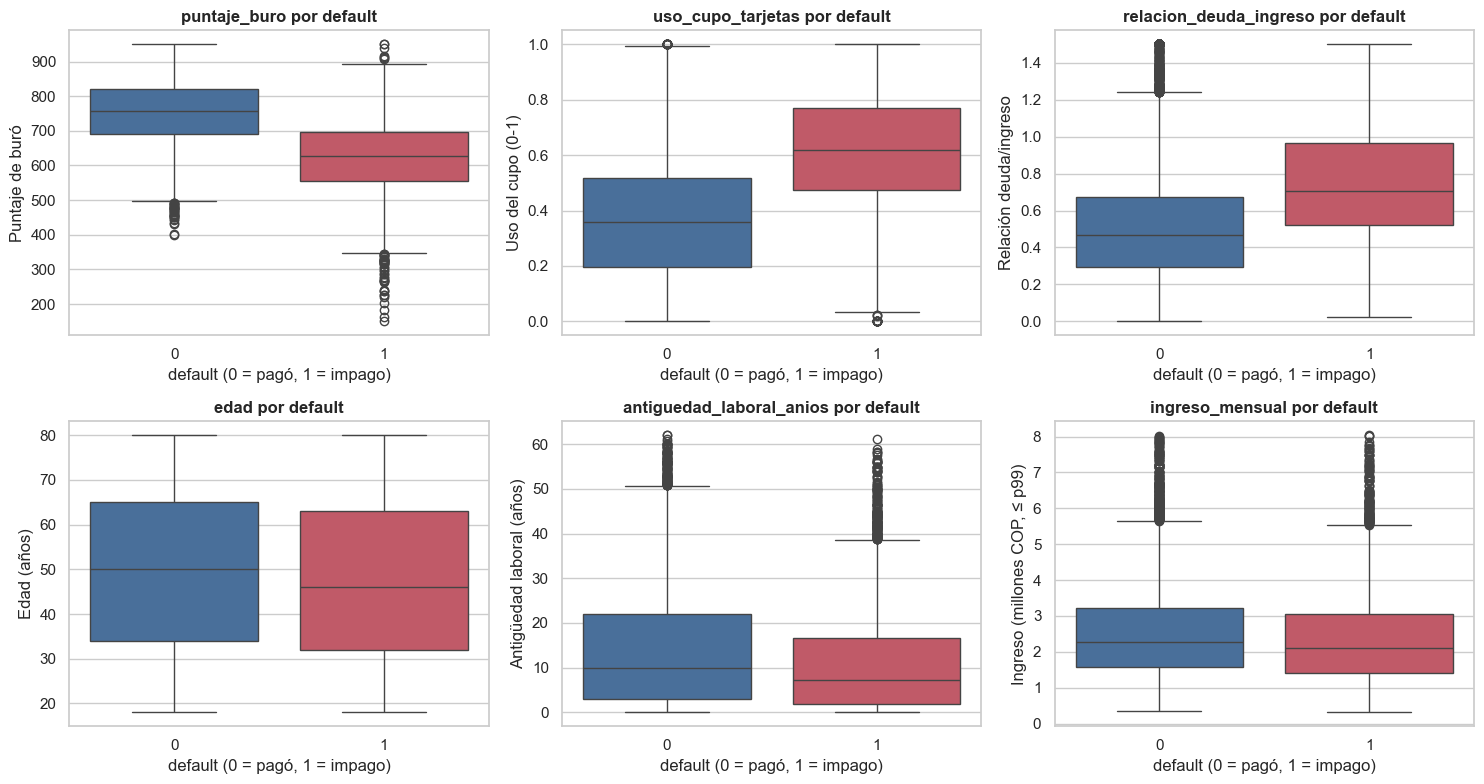

In [28]:
cols_box = [("puntaje_buro", "Puntaje de buró"), ("uso_cupo_tarjetas", "Uso del cupo (0-1)"),
            ("relacion_deuda_ingreso", "Relación deuda/ingreso"), ("edad", "Edad (años)"),
            ("antiguedad_laboral_anios", "Antigüedad laboral (años)"), ("ingreso_mensual", "Ingreso (millones COP, ≤ p99)")]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, yl) in zip(axes.ravel(), cols_box):
    data = df[[col, TARGET]].dropna()
    if col == "edad":
        data = data[data["edad"].between(18, 100)]
    if col == "ingreso_mensual":
        data = data[data[col] <= data[col].quantile(0.99)].assign(ingreso_mensual=lambda x: x[col] / 1e6)
    sns.boxplot(data=data, x=TARGET, y=col, ax=ax, palette=["#3b6ea8", "#d1495b"])
    ax.set_title(f"{col} por default"); ax.set_xlabel("default (0 = pagó, 1 = impago)"); ax.set_ylabel(yl)
plt.tight_layout(); plt.show()

**Interpretación:** las medianas de **puntaje de buró** (≈ 756 vs ≈ 628), **uso del cupo** (≈ 0.36 vs ≈ 0.62) y **deuda/ingreso** (≈ 0.47 vs ≈ 0.71) difieren claramente entre pagadores e impagos. Los impagos son algo **más jóvenes**, con **menos antigüedad laboral** y **ingreso ligeramente menor**; en estas tres últimas las cajas se solapan bastante, por lo que su poder predictivo individual es menor. Se observan bigotes y puntos atípicos en ingreso y antigüedad.

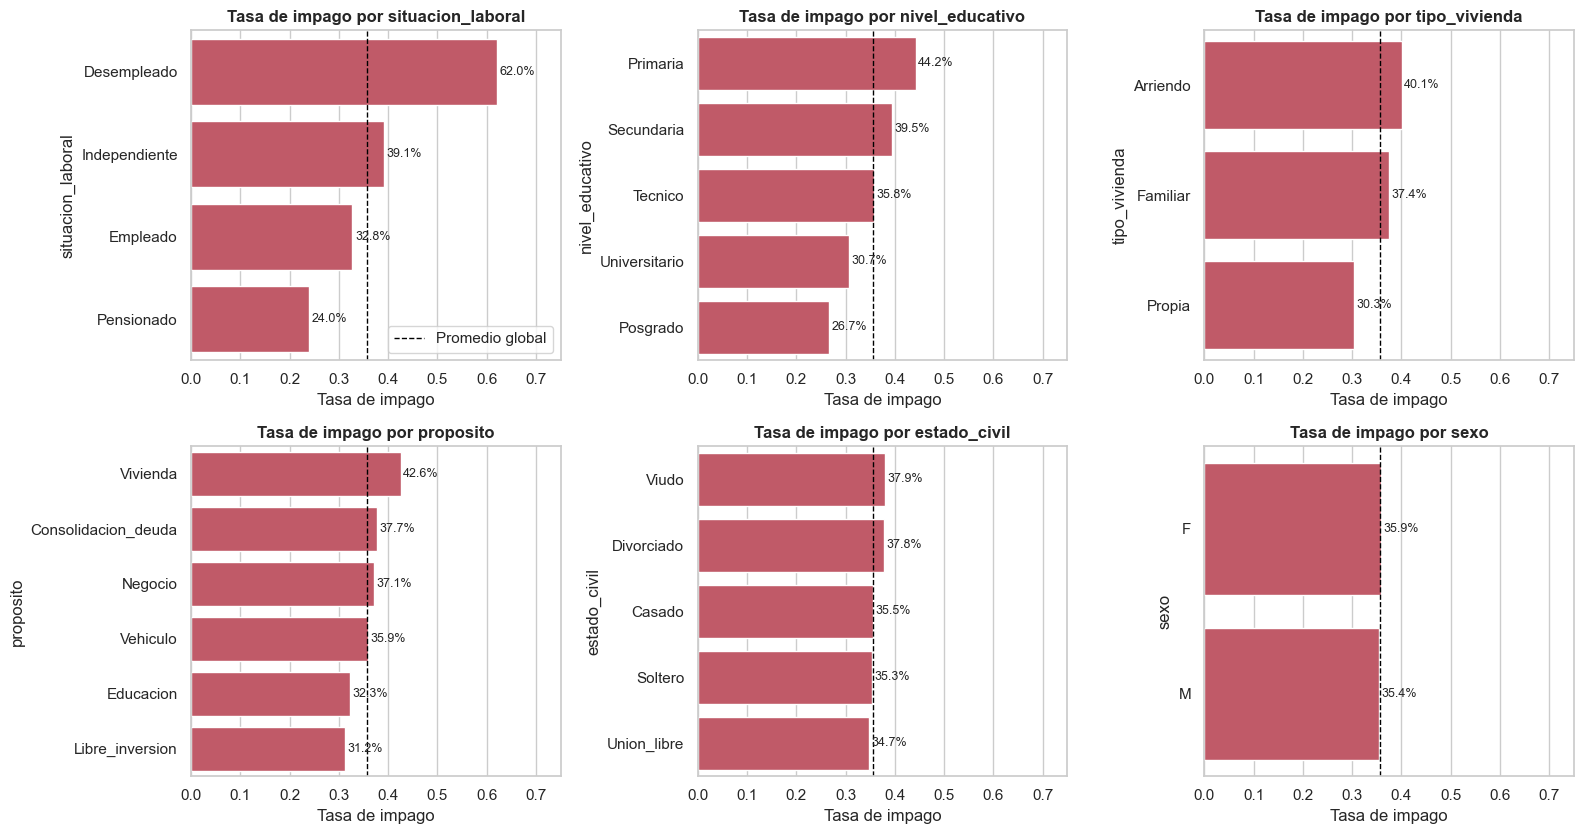

In [29]:
cats = ["situacion_laboral", "nivel_educativo", "tipo_vivienda", "proposito", "estado_civil", "sexo"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, col in zip(axes.ravel(), cats):
    tasa = df.groupby(col)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=tasa.values, y=tasa.index, ax=ax, color="#d1495b")
    ax.axvline(df[TARGET].mean(), ls="--", color="black", lw=1, label="Promedio global")
    ax.set_title(f"Tasa de impago por {col}"); ax.set_xlabel("Tasa de impago"); ax.set_ylabel(col)
    for i, v in enumerate(tasa.values):
        ax.text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=9)
    ax.set_xlim(0, max(0.75, tasa.max() + 0.08))
axes[0, 0].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretación:** **situación laboral** es la categórica más discriminante (desempleados ≈ 62 % de impago frente a pensionados ≈ 24 %); el **nivel educativo** muestra un gradiente claro (Primaria ≈ 44 % → Posgrado ≈ 27 %); **vivienda propia** y créditos de **libre inversión/educación** tienen menor riesgo, y **vivienda** como propósito el mayor. En **sexo** (F ≈ 35.8 % vs M ≈ 35.3 %) y **estado civil** las diferencias son pequeñas: buena noticia para la equidad, y confirma que `sexo` no aporta y no debe usarse.

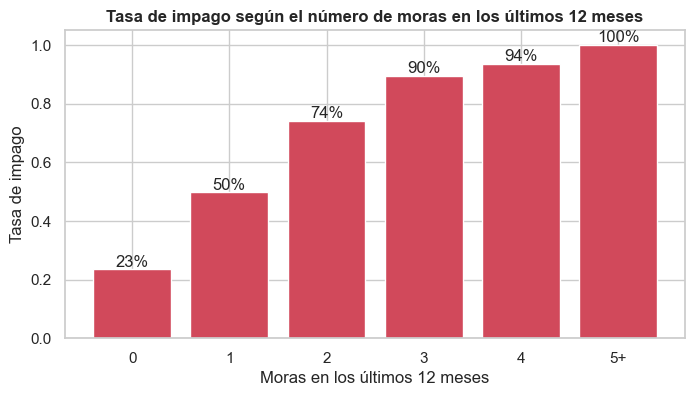

In [30]:
# Moras previas: relación casi monótona con el impago
tasa_moras = df.groupby(df["moras_ultimos_12m"].clip(upper=5))[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tasa_moras.index.astype(str), tasa_moras["mean"], color="#d1495b")
ax.set_xticks(range(len(tasa_moras))); ax.set_xticklabels([str(i) if i < 5 else "5+" for i in tasa_moras.index])
ax.set_title("Tasa de impago según el número de moras en los últimos 12 meses")
ax.set_xlabel("Moras en los últimos 12 meses"); ax.set_ylabel("Tasa de impago")
for i, v in enumerate(tasa_moras["mean"]):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center")
plt.show()

**Interpretación:** la tasa de impago sube de forma casi monótona con las moras previas: ≈ 23 % sin moras, ≈ 50 % con una, ≈ 74 % con dos y > 89 % con tres o más. El historial de pago es uno de los predictores más potentes, lo que justifica crear la variable `tiene_moras_previas` en el notebook 03.

## Conclusiones

- **P1.1–P1.2:** el entorno queda documentado (Jupyter local y Colab) con versiones de librerías y configuración de estilo; las rutas son relativas.
- **P1.3:** 12 144 filas × 21 columnas; **tasa de default ≈ 35.6 %** (desbalance moderado). Problemas de calidad detectados (se tratan en el notebook 03): **nulos** en 7 columnas (`antiguedad_laboral_anios` ≈ 9.2 %, `ingreso_mensual` ≈ 6.2 %, `relacion_deuda_ingreso` ≈ 5 %, `situacion_laboral` ≈ 4 %, `puntaje_buro` ≈ 4 %, `tipo_vivienda` ≈ 3.2 %, `texto_solicitud` ≈ 2 %), **144 duplicados exactos**, **25 edades inválidas** y montos/ingresos con errores de digitación.
- **P1.4:** las operaciones de selección, filtrado, ordenamiento y agregación muestran que las moras previas, el buró bajo con alto uso del cupo y el desempleo elevan fuertemente el impago.
- **P1.5:** se generaron 7 histogramas, 2 diagramas de dispersión, 6 boxplots y gráficos de barras de tasa de impago, todos interpretados.
- **Variables más prometedoras:** `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m`, `relacion_deuda_ingreso`, `situacion_laboral` y `nivel_educativo`. Ingreso y monto discriminan poco por sí solos; se combinarán en ratios. `sexo` no muestra diferencias relevantes y queda excluido como predictor.